<a href="https://colab.research.google.com/github/abigailtassefa/2-2-1-neural-network/blob/main/Inside_the_Backward_Pass_ipynb_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

class Linear:
    def __init__(self, W, b):
        self.W = np.array(W, dtype=float)
        self.b = np.array(b, dtype=float).reshape(1, -1)

        self.x = None
        self.dW = None
        self.db = None

    def forward(self, x):
        self.x = np.asarray(x, dtype=float)
        return self.x @ self.W + self.b

    def backward(self, upstream_grad):
        upstream_grad = np.asarray(upstream_grad, dtype=float)

        self.dW = self.x.T @ upstream_grad
        self.db = np.sum(upstream_grad, axis=0, keepdims=True)

        dx = upstream_grad @ self.W.T
        return dx


# Test handwritten values
W1 = [[0.1, -0.2],
      [0.2,  0.1]]

b1 = [0.0, 0.0]
x = np.array([[1.0, 2.0]])

linear1 = Linear(W1, b1)

z = linear1.forward(x)

print("First layer output:", z)
print("Output shape:", z.shape)


First layer output: [[0.5 0. ]]
Output shape: (1, 2)


In [ ]:
class Sigmoid:
    def __init__(self):
        self.output = None

    def forward(self, x):
        self.output = 1 / (1 + np.exp(-x))
        return self.output

    def backward(self, upstream_grad):
        return upstream_grad * self.output * (1 - self.output)


# Test with the output from Cell 1
sigmoid1 = Sigmoid()

h = sigmoid1.forward(z)

print("Hidden layer output:", h)
print("Output shape:", h.shape)


Hidden layer output: [[0.62245933 0.5       ]]
Output shape: (1, 2)


In [ ]:
# Second Linear layer: 2 hidden neurons -> 1 output
W2 = [[0.3],
      [-0.4]]

b2 = [0.1]

linear2 = Linear(W2, b2)

# Forward pass
y_pred = linear2.forward(h)

print("Final prediction:", y_pred)
print("Output shape:", y_pred.shape)


Final prediction: [[0.0867378]]
Output shape: (1, 1)


In [ ]:

class MSELoss:
    def __init__(self):
        self.y_pred = None
        self.y_true = None

    def forward(self, y_pred, y_true):
        self.y_pred = np.asarray(y_pred, dtype=float)
        self.y_true = np.asarray(y_true, dtype=float)
        return np.mean((self.y_pred - self.y_true) ** 2)

    def backward(self, upstream_grad=1.0):
        n = self.y_pred.size
        return upstream_grad * (2 / n) * (self.y_pred - self.y_true)


# Test with our Phase 1 target
y_true = np.array([[1.0]])

mse_loss = MSELoss()
loss = mse_loss.forward(y_pred, y_true)
loss_grad = mse_loss.backward()

print("MSE Loss:", loss)
print("Loss gradient:", loss_grad)


MSE Loss: 0.8340478471167994
Loss gradient: [[-1.8265244]]


In [ ]:

# Start with the gradient from MSELoss
grad = mse_loss.backward()

# Backward through the output Linear layer
grad = linear2.backward(grad)

# Backward through the Sigmoid activation
grad = sigmoid1.backward(grad)

# Backward through the first Linear layer
grad = linear1.backward(grad)

# Print all parameter gradients
print("=== OUTPUT LAYER ===")
print("dW2:\n", linear2.dW)
print("db2:", linear2.db)

print("\n=== HIDDEN LAYER ===")
print("dW1:\n", linear1.dW)
print("db1:", linear1.db)

print("\n=== INPUT GRADIENT ===")
print("dx:", grad)


=== OUTPUT LAYER ===
dW2:
 [[-1.13693716]
 [-0.9132622 ]]
db2: [[-1.8265244]]

=== HIDDEN LAYER ===
dW1:
 [[-0.128772    0.18265244]
 [-0.25754401  0.36530488]]
db1: [[-0.128772    0.18265244]]

=== INPUT GRADIENT ===
dx: [[-0.04940769 -0.00748916]]


In [ ]:

class ReLU:
    def __init__(self):
        self.input = None

    def forward(self, x):
        self.input = np.asarray(x, dtype=float)
        return np.maximum(0, self.input)

    def backward(self, upstream_grad):
        return upstream_grad * (self.input > 0)


class Tanh:
    def __init__(self):
        self.output = None

    def forward(self, x):
        self.output = np.tanh(x)
        return self.output

    def backward(self, upstream_grad):
        return upstream_grad * (1 - self.output ** 2)


# Test both activations
relu = ReLU()
tanh = Tanh()

print("ReLU forward:", relu.forward(z))
print("ReLU backward:", relu.backward(np.ones_like(z)))

print("Tanh forward:", tanh.forward(z))
print("Tanh backward:", tanh.backward(np.ones_like(z)))


ReLU forward: [[0.5 0. ]]
ReLU backward: [[1. 0.]]
Tanh forward: [[0.46211716 0.        ]]
Tanh backward: [[0.78644773 1.        ]]


In [ ]:

class BCELoss:
    def __init__(self):
        self.y_pred = None
        self.y_true = None

    def forward(self, y_pred, y_true):
        eps = 1e-12

        self.y_pred = np.clip(
            np.asarray(y_pred, dtype=float),
            eps, 1 - eps
        )
        self.y_true = np.asarray(y_true, dtype=float)

        loss = -(
            self.y_true * np.log(self.y_pred)
            + (1 - self.y_true) * np.log(1 - self.y_pred)
        )

        return np.mean(loss)

    def backward(self, upstream_grad=1.0):
        n = self.y_pred.size

        grad = (
            (self.y_pred - self.y_true)
            / (self.y_pred * (1 - self.y_pred))
        ) / n

        return upstream_grad * grad


# Test BCE Loss
bce = BCELoss()

test_pred = np.array([[0.8]])
test_target = np.array([[1.0]])

print("BCE Loss:", bce.forward(test_pred, test_target))
print("BCE Gradient:", bce.backward())


BCE Loss: 0.2231435513142097
BCE Gradient: [[-1.25]]


In [ ]:
class Network:
    def __init__(self, layers):
        self.layers = list(layers)

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def backward(self, upstream_grad):
        for layer in reversed(self.layers):
            upstream_grad = layer.backward(upstream_grad)
        return upstream_grad


# Build our original 2-2-1 network
network = Network([
    linear1,
    sigmoid1,
    linear2
])

# Forward pass
prediction = network.forward(x)
network_loss = mse_loss.forward(prediction, y_true)

# Backward pass
input_grad = network.backward(mse_loss.backward())

# Results
print("=== FORWARD PASS ===")
print("Prediction:", prediction)
print("MSE Loss:", network_loss)

print("\n=== BACKWARD PASS ===")
print("W1 gradients:\n", linear1.dW)
print("b1 gradients:", linear1.db)
print("W2 gradients:\n", linear2.dW)
print("b2 gradients:", linear2.db)

print("\nInput gradient:", input_grad)


=== FORWARD PASS ===
Prediction: [[0.0867378]]
MSE Loss: 0.8340478471167994

=== BACKWARD PASS ===
W1 gradients:
 [[-0.128772    0.18265244]
 [-0.25754401  0.36530488]]
b1 gradients: [[-0.128772    0.18265244]]
W2 gradients:
 [[-1.13693716]
 [-0.9132622 ]]
b2 gradients: [[-1.8265244]]

Input gradient: [[-0.04940769 -0.00748916]]


In [ ]:
#Gradient check
def gradient_check(network, loss_fn, x, y,
                   epsilon=1e-5, tolerance=1e-6):

    # Calculate analytical gradients using backpropagation
    loss_fn.forward(network.forward(x), y)
    network.backward(loss_fn.backward())

    all_passed = True
    max_error = 0.0

    for layer_num, layer in enumerate(network.layers, start=1):
        if not isinstance(layer, Linear):
            continue

        for name in ("W", "b"):
            param = getattr(layer, name)
            analytical = getattr(layer, "d" + name).copy()
            numerical = np.zeros_like(param)

            # Check every individual weight and bias
            for idx in np.ndindex(param.shape):
                original = param[idx]

                try:
                    param[idx] = original + epsilon
                    loss_plus = loss_fn.forward(network.forward(x), y)

                    param[idx] = original - epsilon
                    loss_minus = loss_fn.forward(network.forward(x), y)
                finally:
                    param[idx] = original

                numerical[idx] = (
                    loss_plus - loss_minus
                ) / (2 * epsilon)

            relative_errors = np.abs(
                analytical - numerical
            ) / np.maximum(
                1e-12, np.abs(analytical) + np.abs(numerical)
            )

            for idx in np.ndindex(param.shape):
                error = relative_errors[idx]
                passed = error < tolerance
                all_passed &= bool(passed)
                max_error = max(max_error, float(error))

                print(
                    f"Layer {layer_num} {name}{idx}: "
                    f"analytical={analytical[idx]:.8f}, "
                    f"numerical={numerical[idx]:.8f}, "
                    f"error={error:.2e} "
                    f"{'PASS' if passed else 'FAIL'}"
                )

    # Restore forward/backward caches to the original parameters
    loss_fn.forward(network.forward(x), y)
    network.backward(loss_fn.backward())

    print("\nMaximum relative error:", f"{max_error:.2e}")
    print("FINAL RESULT:", "PASS" if all_passed else "FAIL")

    return all_passed


# Check our original 2-2-1 network
gradient_check(network, mse_loss, x, y_true)


Layer 1 W(0, 0): analytical=-0.12877200, numerical=-0.12877200, error=3.14e-11 PASS
Layer 1 W(0, 1): analytical=0.18265244, numerical=0.18265244, error=1.62e-11 PASS
Layer 1 W(1, 0): analytical=-0.25754401, numerical=-0.25754401, error=1.17e-11 PASS
Layer 1 W(1, 1): analytical=0.36530488, numerical=0.36530488, error=1.41e-11 PASS
Layer 1 b(0, 0): analytical=-0.12877200, numerical=-0.12877200, error=3.14e-11 PASS
Layer 1 b(0, 1): analytical=0.18265244, numerical=0.18265244, error=1.62e-11 PASS
Layer 3 W(0, 0): analytical=-1.13693716, numerical=-1.13693716, error=7.23e-13 PASS
Layer 3 W(1, 0): analytical=-0.91326220, numerical=-0.91326220, error=4.09e-12 PASS
Layer 3 b(0, 0): analytical=-1.82652440, numerical=-1.82652440, error=1.99e-12 PASS

Maximum relative error: 3.14e-11
FINAL RESULT: PASS


True

Inputs:
 [[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]
Targets:
 [[0.]
 [1.]
 [1.]
 [0.]]
Dataset shape: (4, 2)


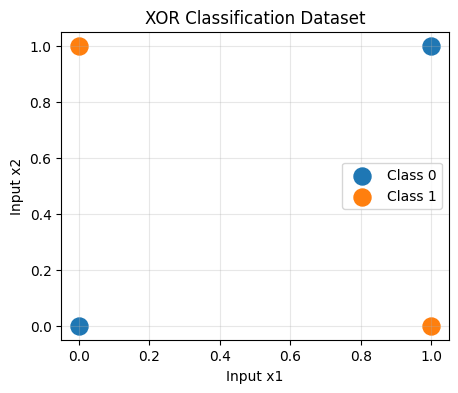

In [ ]:

# XOR dataset: two inputs and one binary target
X_xor = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y_xor = np.array([
    [0],
    [1],
    [1],
    [0]
], dtype=float)

print("Inputs:\n", X_xor)
print("Targets:\n", y_xor)
print("Dataset shape:", X_xor.shape)

# Visualize the dataset
plt.figure(figsize=(5, 4))

for label in [0, 1]:
    mask = y_xor.ravel() == label
    plt.scatter(
        X_xor[mask, 0],
        X_xor[mask, 1],
        s=150,
        label=f"Class {label}"
    )

plt.xlabel("Input x1")
plt.ylabel("Input x2")
plt.title("XOR Classification Dataset")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [ ]:

# Reproducible random initialization
rng = np.random.default_rng(42)

# Hidden layer: 2 inputs -> 2 neurons
xor_linear1 = Linear(
    rng.normal(0, 1, (2, 2)),
    np.zeros(2)
)

# Output layer: 2 neurons -> 1 prediction
xor_linear2 = Linear(
    rng.normal(0, 1, (2, 1)),
    np.zeros(1)
)

# Assemble the 2-2-1 network
xor_network = Network([
    xor_linear1,
    Sigmoid(),
    xor_linear2,
    Sigmoid()
])

xor_loss = BCELoss()

# Check predictions before training
initial_predictions = xor_network.forward(X_xor)
initial_loss = xor_loss.forward(initial_predictions, y_xor)

print("Predictions before training:")
print(initial_predictions)

print("\nInitial BCE loss:", initial_loss)
print("Network architecture: 2 -> 2 -> 1")


Predictions before training:
[[0.16429565]
 [0.09433316]
 [0.1879975 ]
 [0.11244935]]

Initial BCE loss: 1.0827547819841383
Network architecture: 2 -> 2 -> 1


In [ ]:

# Training settings
learning_rate = 1.0
epochs = 3000
xor_losses = []

# Train using full-batch gradient descent
for epoch in range(epochs):

    # Forward pass
    predictions = xor_network.forward(X_xor)
    loss = xor_loss.forward(predictions, y_xor)
    xor_losses.append(loss)

    # Backward pass
    xor_network.backward(xor_loss.backward())

    # Update weights and biases
    for layer in xor_network.layers:
        if isinstance(layer, Linear):
            layer.W -= learning_rate * layer.dW
            layer.b -= learning_rate * layer.db

    if (epoch + 1) % 500 == 0:
        print(f"Epoch {epoch + 1}: Loss = {loss:.6f}")

# Evaluate the trained model
final_predictions = xor_network.forward(X_xor)
predicted_classes = (final_predictions >= 0.5).astype(int)
accuracy = np.mean(predicted_classes == y_xor)

print("\nFinal predictions:\n", final_predictions)
print("Predicted classes:", predicted_classes.ravel())
print("Actual classes:   ", y_xor.ravel().astype(int))
print(f"Training accuracy: {accuracy * 100:.2f}%")


Epoch 500: Loss = 0.174675
Epoch 1000: Loss = 0.031895
Epoch 1500: Loss = 0.016914
Epoch 2000: Loss = 0.011442
Epoch 2500: Loss = 0.008628
Epoch 3000: Loss = 0.006918

Final predictions:
 [[0.00608836]
 [0.9919384 ]
 [0.99200144]
 [0.00541311]]
Predicted classes: [0 1 1 0]
Actual classes:    [0 1 1 0]
Training accuracy: 100.00%


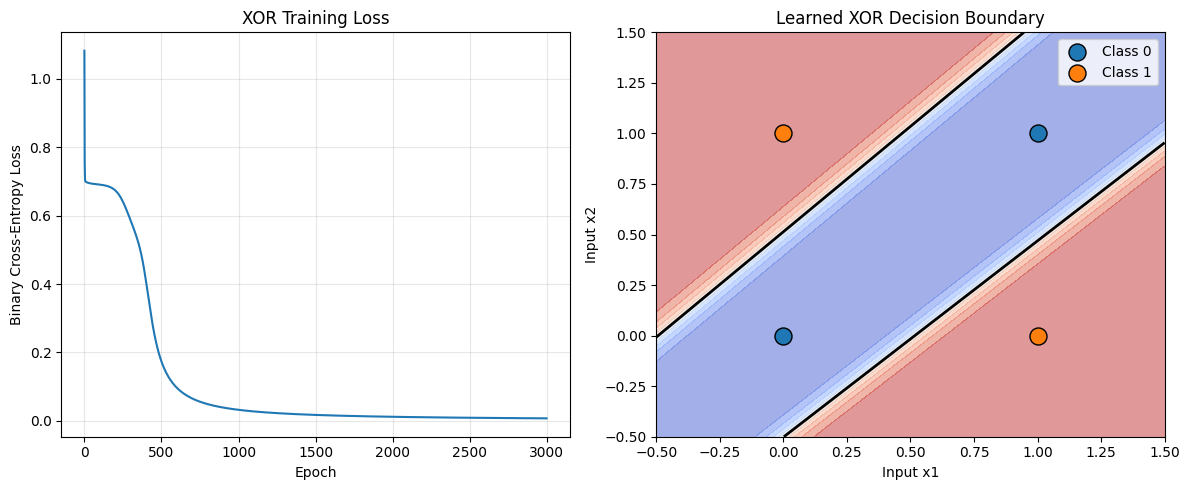

In [ ]:

# Create a grid of points for the decision boundary
xx, yy = np.meshgrid(
    np.linspace(-0.5, 1.5, 200),
    np.linspace(-0.5, 1.5, 200)
)

grid_points = np.c_[xx.ravel(), yy.ravel()]

# Predict probabilities across the grid
grid_predictions = xor_network.forward(grid_points)
probabilities = grid_predictions.reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Training loss
axes[0].plot(xor_losses)
axes[0].set_title("XOR Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].grid(alpha=0.3)

# Plot 2: Learned decision boundary
axes[1].contourf(
    xx, yy, probabilities,
    levels=np.linspace(0, 1, 11),
    cmap="coolwarm",
    alpha=0.5
)

axes[1].contour(
    xx, yy, probabilities,
    levels=[0.5],
    colors="black",
    linewidths=2
)

for label in [0, 1]:
    mask = y_xor.ravel() == label

    axes[1].scatter(
        X_xor[mask, 0],
        X_xor[mask, 1],
        s=150,
        edgecolors="black",
        label=f"Class {label}"
    )

axes[1].set_title("Learned XOR Decision Boundary")
axes[1].set_xlabel("Input x1")
axes[1].set_ylabel("Input x2")
axes[1].legend()

plt.tight_layout()
plt.show()


In [ ]:

# Create a linear baseline: 2 inputs -> 1 output
baseline_rng = np.random.default_rng(42)

baseline_linear = Linear(
    baseline_rng.normal(0, 1, (2, 1)),
    np.zeros(1)
)

baseline_network = Network([
    baseline_linear,
    Sigmoid()
])

baseline_loss = BCELoss()
baseline_losses = []

# Train using the same settings as our neural network
for epoch in range(epochs):

    predictions = baseline_network.forward(X_xor)
    loss = baseline_loss.forward(predictions, y_xor)
    baseline_losses.append(loss)

    baseline_network.backward(baseline_loss.backward())

    baseline_linear.W -= learning_rate * baseline_linear.dW
    baseline_linear.b -= learning_rate * baseline_linear.db

# Evaluate the linear baseline
baseline_predictions = baseline_network.forward(X_xor)
baseline_final_loss = baseline_loss.forward(
    baseline_predictions, y_xor
)
baseline_classes = (baseline_predictions >= 0.5).astype(int)
baseline_accuracy = np.mean(baseline_classes == y_xor)

# Evaluate the trained neural network under the same conditions
nn_predictions = xor_network.forward(X_xor)
nn_final_loss = xor_loss.forward(nn_predictions, y_xor)
nn_accuracy = np.mean(
    (nn_predictions >= 0.5).astype(int) == y_xor
)

print("=== LINEAR BASELINE ===")
print("Predictions:\n", baseline_predictions)
print(f"Final BCE Loss: {baseline_final_loss:.6f}")
print(f"Training Accuracy: {baseline_accuracy * 100:.2f}%")

print("\n=== 2-2-1 NEURAL NETWORK ===")
print(f"Final BCE Loss: {nn_final_loss:.6f}")
print(f"Training Accuracy: {nn_accuracy * 100:.2f}%")


=== LINEAR BASELINE ===
Predictions:
 [[0.5]
 [0.5]
 [0.5]
 [0.5]]
Final BCE Loss: 0.693147
Training Accuracy: 50.00%

=== 2-2-1 NEURAL NETWORK ===
Final BCE Loss: 0.006915
Training Accuracy: 100.00%


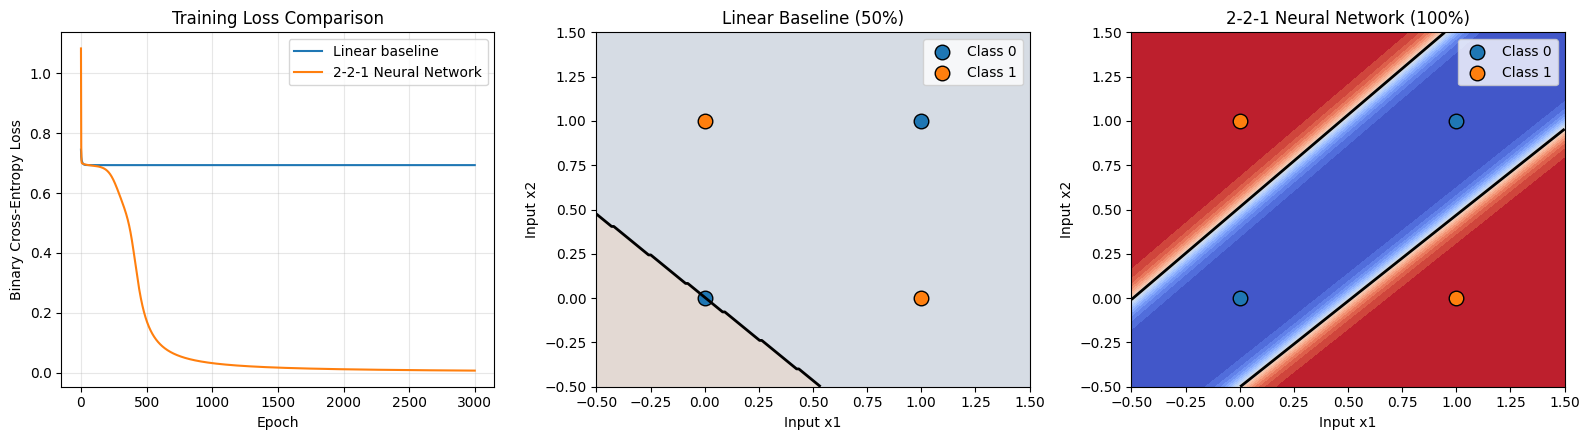

In [ ]:

# Generate a shared evaluation grid
gx, gy = np.meshgrid(
    np.linspace(-0.5, 1.5, 200),
    np.linspace(-0.5, 1.5, 200)
)
grid = np.column_stack((gx.ravel(), gy.ravel()))

baseline_probs = baseline_network.forward(grid).reshape(gx.shape)
nn_probs = xor_network.forward(grid).reshape(gx.shape)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Graph 1: Compare training loss
axes[0].plot(baseline_losses, label="Linear baseline")
axes[0].plot(xor_losses, label="2-2-1 Neural Network")
axes[0].set_title("Training Loss Comparison")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Graphs 2 and 3: Compare prediction regions
for ax, probs, title in zip(
    axes[1:],
    [baseline_probs, nn_probs],
    ["Linear Baseline (50%)", "2-2-1 Neural Network (100%)"]
):
    ax.contourf(
        gx, gy, probs,
        levels=np.linspace(0, 1, 21),
        cmap="coolwarm",
        vmin=0, vmax=1
    )

    # The 0.5 contour is the decision boundary,
    # if it exists inside the plotted area.
    if probs.min() < 0.5 < probs.max():
        ax.contour(
            gx, gy, probs,
            levels=[0.5],
            colors="black",
            linewidths=2
        )

    for label in [0, 1]:
        mask = y_xor.ravel() == label
        ax.scatter(
            X_xor[mask, 0],
            X_xor[mask, 1],
            s=110,
            edgecolors="black",
            label=f"Class {label}"
        )

    ax.set_title(title)
    ax.set_xlabel("Input x1")
    ax.set_ylabel("Input x2")
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()


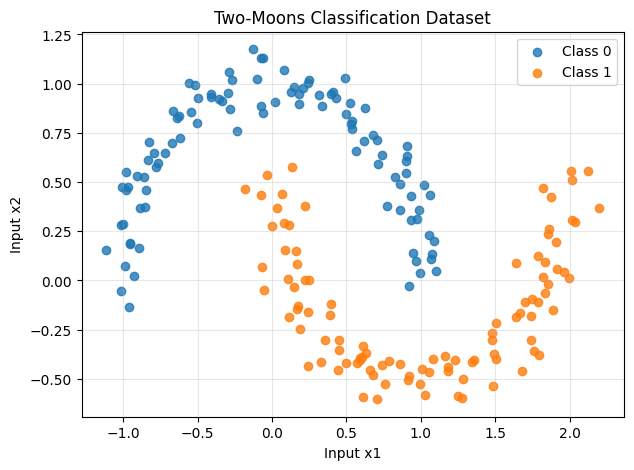

Total samples: 200
Training samples: 160
Testing samples: 40


In [ ]:
#TWO moon experiment

# Generate two moons using NumPy only
moons_rng = np.random.default_rng(123)

n_per_class = 100
noise = 0.08

theta = np.linspace(0, np.pi, n_per_class)

# First moon (upper semicircle)
moon0 = np.column_stack([
    np.cos(theta),
    np.sin(theta)
])

# Second moon (lower semicircle)
moon1 = np.column_stack([
    1 - np.cos(theta),
    0.5 - np.sin(theta)
])

# Combine and add noise
X_moons = np.vstack([moon0, moon1])
X_moons += moons_rng.normal(0, noise, X_moons.shape)

y_moons = np.vstack([
    np.zeros((n_per_class, 1)),
    np.ones((n_per_class, 1))
])

# Stratified 80/20 training/test split
train_idx = []
test_idx = []

for label in [0, 1]:
    indices = np.where(y_moons.ravel() == label)[0]
    moons_rng.shuffle(indices)

    train_idx.extend(indices[:80])
    test_idx.extend(indices[80:])

train_idx = np.array(train_idx)
test_idx = np.array(test_idx)

moons_rng.shuffle(train_idx)
moons_rng.shuffle(test_idx)

X_moons_train = X_moons[train_idx]
y_moons_train = y_moons[train_idx]

X_moons_test = X_moons[test_idx]
y_moons_test = y_moons[test_idx]

# Visualize the dataset
plt.figure(figsize=(7, 5))

for label in [0, 1]:
    mask = y_moons.ravel() == label
    plt.scatter(
        X_moons[mask, 0],
        X_moons[mask, 1],
        label=f"Class {label}",
        alpha=0.8
    )

plt.title("Two-Moons Classification Dataset")
plt.xlabel("Input x1")
plt.ylabel("Input x2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Total samples:", len(X_moons))
print("Training samples:", len(X_moons_train))
print("Testing samples:", len(X_moons_test))


In [ ]:

# Fresh 2-2-1 neural network for two moons
moons_init_rng = np.random.default_rng(42)

moons_network = Network([
    Linear(
        moons_init_rng.normal(0, 1, (2, 2)),
        np.zeros(2)
    ),
    Sigmoid(),
    Linear(
        moons_init_rng.normal(0, 1, (2, 1)),
        np.zeros(1)
    ),
    Sigmoid()
])

moons_loss = BCELoss()

# Same training settings as XOR
moons_lr = 1.0
moons_epochs = 3000
moons_losses = []

# Training loop
for epoch in range(moons_epochs):

    predictions = moons_network.forward(X_moons_train)
    loss = moons_loss.forward(predictions, y_moons_train)
    moons_losses.append(loss)

    moons_network.backward(moons_loss.backward())

    for layer in moons_network.layers:
        if isinstance(layer, Linear):
            layer.W -= moons_lr * layer.dW
            layer.b -= moons_lr * layer.db

    if (epoch + 1) % 500 == 0:
        print(f"Epoch {epoch + 1}: Loss = {loss:.6f}")

# Evaluate training performance
train_probs = moons_network.forward(X_moons_train)
train_predictions = (train_probs >= 0.5).astype(int)
train_accuracy = np.mean(train_predictions == y_moons_train)
train_loss = moons_loss.forward(train_probs, y_moons_train)

# Evaluate unseen test data
test_probs = moons_network.forward(X_moons_test)
test_predictions = (test_probs >= 0.5).astype(int)
test_accuracy = np.mean(test_predictions == y_moons_test)
test_loss = moons_loss.forward(test_probs, y_moons_test)

print("\n=== TWO MOONS RESULTS ===")
print("Architecture: 2 -> 2 -> 1")
print(f"Training accuracy: {train_accuracy * 100:.2f}%")
print(f"Testing accuracy:  {test_accuracy * 100:.2f}%")
print(f"Training BCE loss: {train_loss:.6f}")
print(f"Testing BCE loss:  {test_loss:.6f}")


Epoch 500: Loss = 0.254172
Epoch 1000: Loss = 0.250565
Epoch 1500: Loss = 0.246845
Epoch 2000: Loss = 0.242517
Epoch 2500: Loss = 0.238610
Epoch 3000: Loss = 0.235790

=== TWO MOONS RESULTS ===
Architecture: 2 -> 2 -> 1
Training accuracy: 90.00%
Testing accuracy:  85.00%
Training BCE loss: 0.235785
Testing BCE loss:  0.350437


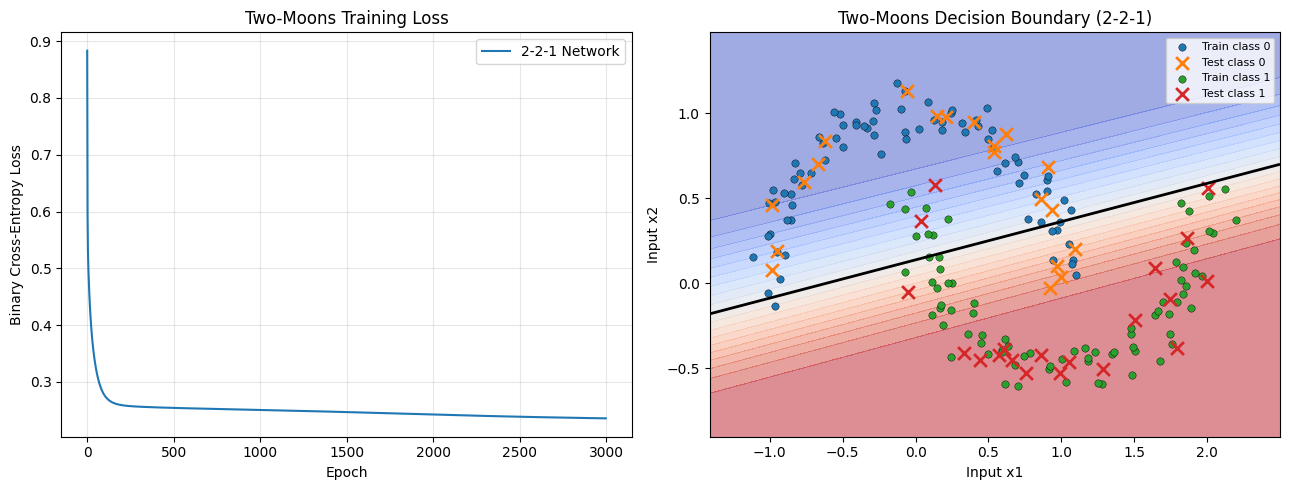

In [ ]:

# Create a grid covering the two-moons dataset
x_min, x_max = X_moons[:, 0].min() - 0.3, X_moons[:, 0].max() + 0.3
y_min, y_max = X_moons[:, 1].min() - 0.3, X_moons[:, 1].max() + 0.3

mx, my = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.column_stack([mx.ravel(), my.ravel()])

# Predict probabilities across the grid
moon_probs = moons_network.forward(grid).reshape(mx.shape)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Graph 1: Training loss
axes[0].plot(moons_losses, label="2-2-1 Network")
axes[0].set_title("Two-Moons Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Binary Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Graph 2: Decision boundary
axes[1].contourf(
    mx, my, moon_probs,
    levels=np.linspace(0, 1, 21),
    cmap="coolwarm",
    alpha=0.5
)

axes[1].contour(
    mx, my, moon_probs,
    levels=[0.5],
    colors="black",
    linewidths=2
)

# Plot training and testing samples separately
for label in [0, 1]:
    train_mask = y_moons_train.ravel() == label
    test_mask = y_moons_test.ravel() == label

    axes[1].scatter(
        X_moons_train[train_mask, 0],
        X_moons_train[train_mask, 1],
        s=28,
        marker="o",
        edgecolors="black",
        linewidths=0.3,
        label=f"Train class {label}"
    )

    axes[1].scatter(
        X_moons_test[test_mask, 0],
        X_moons_test[test_mask, 1],
        s=85,
        marker="x",
        linewidths=2,
        label=f"Test class {label}"
    )

axes[1].set_title("Two-Moons Decision Boundary (2-2-1)")
axes[1].set_xlabel("Input x1")
axes[1].set_ylabel("Input x2")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()
